<a href="https://colab.research.google.com/github/13rustam/Zhanakorgan_Agriculture/blob/main/3.%20PyStac_Land_Cover.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pystac-client stackstac

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 5.1 MB/s eta 0:00:00


In [2]:
from pystac_client import Client

In [3]:
catalog = Client.open(
    'https://earth-search.aws.element84.com/v1'
)

In [4]:
for collections in catalog.get_collections():
  print(collections.id)

sentinel-2-pre-c1-l2a
cop-dem-glo-30
naip
cop-dem-glo-90
landsat-c2-l2
sentinel-2-l2a
sentinel-2-l1c
sentinel-2-c1-l2a
sentinel-1-grd


In [5]:
roi = [67.385593, 43.362794, 67.561351, 43.456266]

In [6]:
search = catalog.search(
    collections = ['sentinel-2-c1-l2a'],
    bbox = roi,
    datetime = '2023/2025',
    query = {'eo:cloud_cover':{'lt':'10'}}
)

In [7]:
items = search.item_collection()

/usr/local/lib/python3.13/dist-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


In [8]:
len(items)

195

In [9]:
items[0]

<Item id=S2C_T42TUP_20251222T063307_L2A>

In [10]:
import stackstac

In [11]:
items[0].assets.keys()

dict_keys(['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail'])

In [12]:
ds = stackstac.stack(
    items,
    bounds_latlon = roi,
    assets = ['red','nir'],
    epsg = 3857,
    resolution = 30
)

In [13]:
ds_clean = (
    ds.to_dataset('band')
    .drop_dims('band')
    .reset_coords(drop = True)
    .drop_attrs()
)

In [14]:
red = ds_clean['red']
nir = ds_clean['nir']

In [15]:
ndvi = (nir - red) / (nir + red)

In [16]:
ndvi_monthly = ndvi.resample(time = 'M').max('time')

/usr/local/lib/python3.13/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(


In [17]:
from dask.diagnostics import ProgressBar

In [18]:
import warnings
warnings.filterwarnings('ignore', category = RuntimeWarning)
import logging
logging.getLogger('rasterio._env').setLevel(logging.ERROR)

In [19]:
with ProgressBar():
  ndvi_monthly = ndvi_monthly.compute()

[########################################] | 100% Completed | 147.14 s


In [20]:
ndvi_month = ndvi_monthly.groupby('time.month').mean('time')

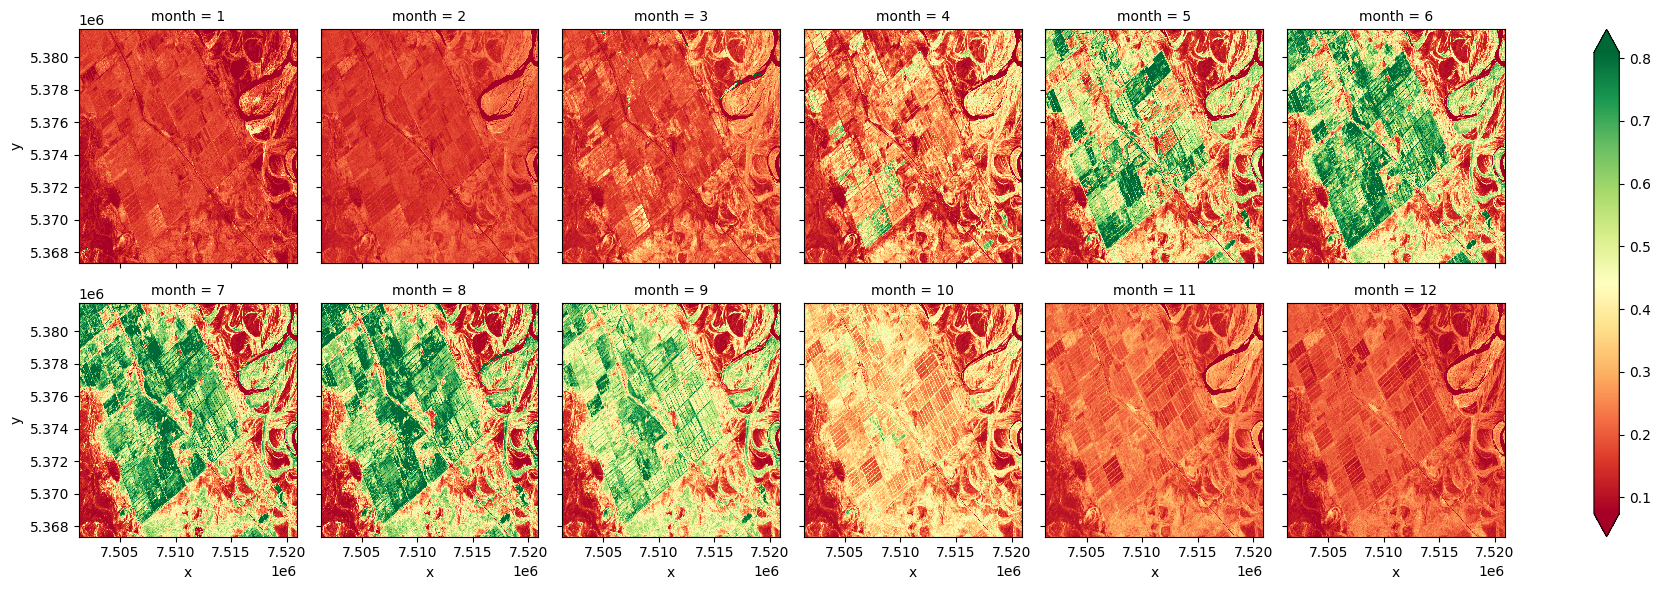

In [21]:
ndvi_month.plot(
    robust = True, cmap = 'RdYlGn', col = 'month',
    col_wrap = 6
)

In [22]:
import xarray as xr

In [23]:
ndvi_classes = xr.where(
    ndvi_monthly < 0, 1,
    xr.where(
    ndvi_monthly < 0.2, 2,
    xr.where(
    ndvi_monthly < 0.4, 3,
    xr.where(
    ndvi_monthly < 0.6, 4, 5
    )))
)

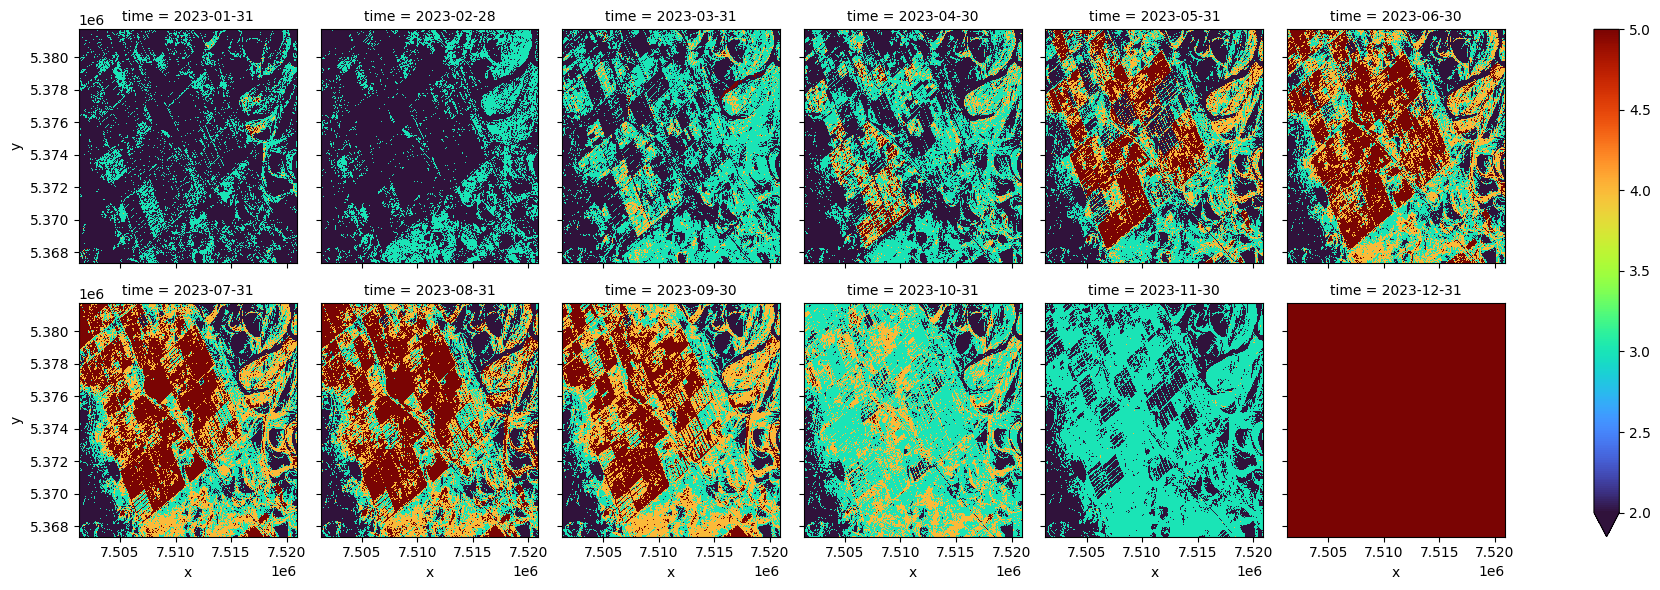

In [24]:
ndvi_classes.sel(time = '2023').plot(
    robust =True, cmap = 'turbo', col = 'time', col_wrap = 6
)

In [25]:
from scipy import stats

In [26]:
ndvi_classes.shape[0]

36

In [27]:
ndvi_mode = stats.mode(
    ndvi_classes.values,
    axis = 0,
    nan_policy = 'omit'
).mode

In [28]:
ndvi_mode = (
    xr.DataArray(
        ndvi_mode,
        coords = {'y': ndvi_classes.y, 'x': ndvi_classes.x},
        dims = ['y', 'x']
    )
)

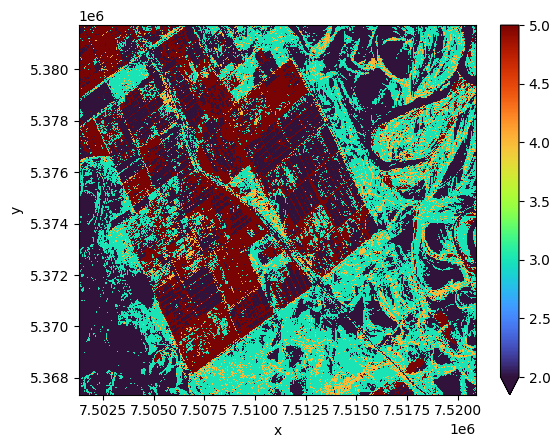

In [29]:
ndvi_mode.plot(
    robust = True, cmap = 'turbo'
)

In [30]:
import numpy as np

In [31]:
cls_num = np.unique(ndvi_mode.values)

In [32]:
for i in cls_num:
  pixels = ndvi_mode.isin(i).sum(dim = ['y','x']).item()
  area = (pixels * (30 * 30)) / 1e6
  print(f'class {i} pixels: {pixels}')
  print(f'class {i} area: {area} km2')

class 1 pixels: 3809
class 1 area: 3.4281 km2
class 2 pixels: 123498
class 2 area: 111.1482 km2
class 3 pixels: 101572
class 3 area: 91.4148 km2
class 4 pixels: 23993
class 4 area: 21.5937 km2
class 5 pixels: 59915
class 5 area: 53.9235 km2
